# 8. Questão: Procure responder um problema econômico por meio de uma base de dados da biblioteca Applied Econometrics with R (AER)

A base de dados escolhida foi à CPS1985 que contem: Salários, educação, experiência e características dos trabalhadores.

Foram escolhida as variaveis quantitativas: 
* `wage`- salário 
* `education` - educação 
* `experience` - experiência 

Procura-se ver se existe uma relação entre sálario e educação, tendo como variaveis de controle à experiência

In [1]:
# Importando pacotes

#Pacote matematica
import numpy as np 

# Pacote para trazer os dados da AER e econometria
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats.api as sms 

# Pacote para manipulação de dataframes
import pandas as pd

# Pacote para visualização de graficos
import matplotlib.pyplot as plt

In [77]:
# Guardando base de dados CPS1985 e filtrando as variaveis
df = sm.datasets.get_rdataset("CPS1985",  "AER").data
df = df[["wage","education", "experience"]]


In [78]:
# Visualização rapida da tabela
df.head()

,wage,education,experience
rownames,,,
1,5.10,8,21
1100,4.95,9,42
2,6.67,12,1
3,4.00,12,4
4,7.50,12,17


## a) Ilustre o problema a partir de gráficos, transformações logarítmicas, e estatística descritiva, entre outras.

### Estatística descritiva 

In [79]:
df.describe()

,wage,education,experience
count,534.000000,534.000000,534.000000
mean,9.024064,13.018727,17.822097
std,5.139097,2.615373,12.379710
min,1.000000,2.000000,0.000000
25%,5.250000,12.000000,8.000000
50%,7.780000,12.000000,15.000000
75%,11.250000,15.000000,26.000000
max,44.500000,18.000000,55.000000


#### Gráfico Salário X Educação

Text(0.5, 1.0, 'ln(Sálario) x Educação')

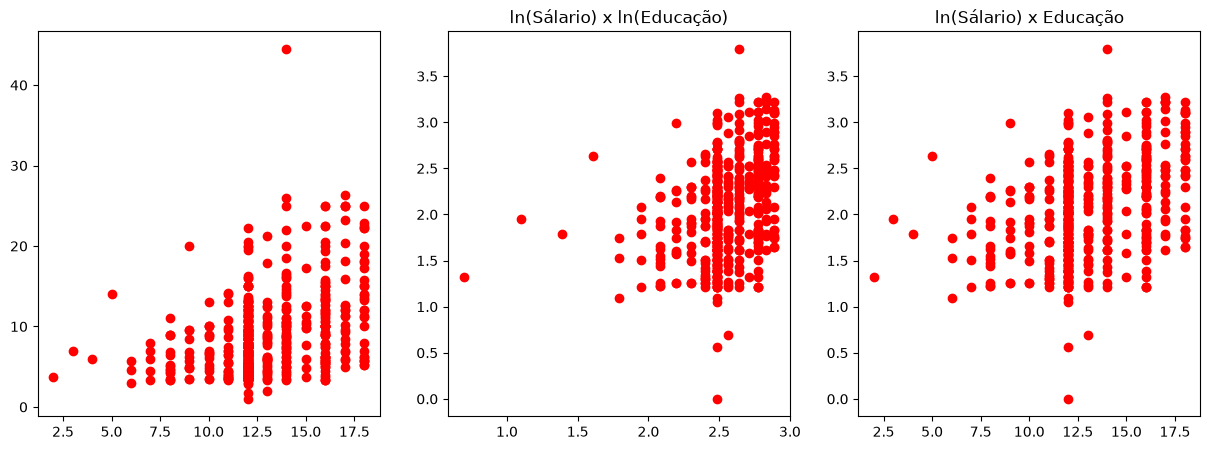

In [80]:
y = df["wage"]
x = df["education"]

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize = (15, 5))

ax1.scatter(x, y, color='red')
ax2.set_title("Sálario x Educação")

ax2.scatter(np.log(x), np.log(y), color='red')
ax2.set_title("ln(Sálario) x ln(Educação)")

ax3.scatter(x, np.log(y), color='red')
ax3.set_title("ln(Sálario) x Educação")


## b) Calcule e interprete o efeito marginal e a elasticidade; mostre as implicações de escolher a forma funcional incorreta.

### Modelo log-linear
$$ ln(wage) = \beta_0 + \beta_1education + \beta_2experience

#### Regressão multipla (MQO)

In [81]:
# ln do sálario
df["ln_wage"] = np.log(df["wage"])

In [82]:
# ln da educação
df["ln_education"] = np.log(df["education"])

In [86]:
# Fazendo regressão da forma funcional log-lin e log_log (para calcular a elasticidade)
modelo_log_lin = smf.ols('ln_wage ~ education + experience', data = df).fit()
modelo_log_log = smf.ols('ln_wage ~ ln_education + experience', data = df).fit()

In [84]:
# Resultado log-lin
modelo_log_lin.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                ln_wage   R-squared:                       0.211
Model:                            OLS   Adj. R-squared:                  0.209
Method:                 Least Squares   F-statistic:                     71.21
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           3.99e-28
Time:                        15:56:51   Log-Likelihood:                -352.46
No. Observations:                 534   AIC:                             710.9
Df Residuals:                     531   BIC:                             723.8
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.5942      0.124      4.775      0.000       0.350       0.839
education      0.0964      0.008     11.603      0.000       0.080       0.113
experience     0.0118      0.002      6.707      0.000       0.008       0.015
==============================================================================
Omnibus:                        3.895   Durbin-Watson:                   1.781
Prob(Omnibus):                  0.143   Jarque-Bera (JB):                4.436
Skew:                          -0.071   Prob(JB):                        0.109
Kurtosis:                       3.423   Cond. No.                         149.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [87]:
modelo_log_log.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                ln_wage   R-squared:                       0.182
Model:                            OLS   Adj. R-squared:                  0.179
Method:                 Least Squares   F-statistic:                     59.06
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           6.93e-24
Time:                        16:05:36   Log-Likelihood:                -362.28
No. Observations:                 534   AIC:                             730.6
Df Residuals:                     531   BIC:                             743.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -0.7281      0.260     -2.802      0.005      -1.238      -0.218
ln_education     1.0144      0.096     10.516      0.000       0.825       1.204
experience       0.0117      0.002      6.463      0.000       0.008       0.015
==============================================================================
Omnibus:                        3.037   Durbin-Watson:                   1.733
Prob(Omnibus):                  0.219   Jarque-Bera (JB):                3.379
Skew:                          -0.022   Prob(JB):                        0.185
Kurtosis:                       3.387   Cond. No.                         292.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Forma funcional:

A especificação linear-linear tradicional revela-se inadequada tanto do ponto de vista teórico quanto estatístico. Economicamente, a teoria do capital humano postua que o retorno da educação sobre os rendimentos não ocorre a uma taxa absoluta constante (em dólares ou unidades monetárias fixas), mas sim a uma taxa percentual crescente. Ou seja, cada ano adicional de escolaridade tende a elevar o salário do indivíduo em um percentual aproximado e constante, o que caracteriza uma relação exponencial que é linearizada por meio de uma transformação logarítmica.


Do ponto de vista empírico e diagnóstico, a inspeção gráfica preliminar e as estatísticas descritivas evidenciam que a variável salário (wage) apresenta assimetria à direita e alta dispersão.


### Efeito marginal
O modelo log-linear estimado via MQO, apresenta um bom ajuste geral, com um $R^2$ de 0,211 e estatística F altamente significativa. Os coeficientes das variáveis de escolaridade (education) e experiência (experience) são estatisticamente significantes ($p < 0.001$), indicando que cada ano adicional de educação está associado a um acréscimo aproximado de 9,64% no salário (nesta forma funcional temos uma semi-elasticidade) **ESTE É O EFEITO MARGINAL**, enquanto cada ano de experiência eleva o rendimento em cerca de 1,18%. Além disso, os testes diagnósticos de resíduos (Jarque-Bera) apresentam p-valores superiores a 0,05, o que confirma a normalidade dos erros e valida a adequação da forma funcional escolhida.

### Elasticidade

No modelo log-log estimado, o coeficiente associado à variável ln_education representa a elasticidade-rendimento do salário em relação à educação, registrando um valor de 1,0144 com alta significância estatística ($p < 0,001$). Isso indica que a relação entre educação e salário é praticamente unilástica: para cada aumento de 1% nos anos de estudo, espera-se uma elevação de aproximadamente 1,01% no salário do trabalhador, mantendo a experiência constante.

## c) Cálcule intervalo de confiança para os estimadores com níveis de significância de 1%, 5% e 10%.

In [89]:
# Níveis de significância: alpha = 0.10 (10%), 0.05 (5%), 0.01 (1%)
for alpha in [0.10, 0.05, 0.01]:
    conf = int((1 - alpha) * 100)
    print(f"\n--- Intervalos de Confiança de {conf}% (Significância de {int(alpha*100)}%) ---")
    
    print("\n[Modelo Log-Linear]")
    print(modelo_log_lin.conf_int(alpha=alpha).rename(columns={0: 'Infeiro', 1: 'Superior'}))


--- Intervalos de Confiança de 90% (Significância de 10%) ---

[Modelo Log-Linear]
             Infeiro  Superior
Intercept   0.389145  0.799192
education   0.082722  0.110106
experience  0.008881  0.014667

--- Intervalos de Confiança de 95% (Significância de 5%) ---

[Modelo Log-Linear]
             Infeiro  Superior
Intercept   0.349737  0.838600
education   0.080090  0.112738
experience  0.008325  0.015223

--- Intervalos de Confiança de 99% (Significância de 1%) ---

[Modelo Log-Linear]
             Infeiro  Superior
Intercept   0.272507  0.915830
education   0.074932  0.117895
experience  0.007236  0.016312


## d) Qual é a relação entre o nível de significância e rigor estatístico?
O nível de significância ($\alpha$) representa a probabilidade máxima tolerável de cometer um erro de tipo 1, ou seja, de rejeitar a hipótese nula quando ela é verdadeira. Quanto menor for o nível de significância escolhido, maior e mais exigente torna-se a região de rejeição, resultando em um rigor estatístico mais elevado. Em termos práticos, um nível de significância mais baixo diminui a margem para falsos positivos e exige evidências empíricas significativamente mais fortes nos dados para que se possa afirmar que um coeficiente de regressão é estatisticamente diferente de zero.

## e) Utilize variáveis de interações e interprete o efeito marginal e a elasticidade do modelo.

Modelo com variavel de interação (ln_education * experience):

$$ ln(wage) = \beta_0 + \beta_1education + \beta_2experience + \beta_3(education * experience) $$

In [90]:
# Criando a variável de interação no DataFrame
df['edu_exp'] = df['education'] * df['experience']

# Modelo log-linear com termo de interação
modelo_interacao = smf.ols('ln_wage ~ education + experience + edu_exp', data=df).fit()
print(modelo_interacao.summary())

                            OLS Regression Results                            
Dep. Variable:                ln_wage   R-squared:                       0.212
Model:                            OLS   Adj. R-squared:                  0.207
Method:                 Least Squares   F-statistic:                     47.46
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           3.52e-27
Time:                        16:20:31   Log-Likelihood:                -352.38
No. Observations:                 534   AIC:                             712.8
Df Residuals:                     530   BIC:                             729.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.6580      0.198      3.318      0.0

Derivando em relação à educação, o efeito marginal da educação passa a ser :

$$ \beta_1 + \beta_3 * experience $$

Ou seja:

$$ 0,0914 + 0,0002 * experience $$

Enquanto à elasticidade:

$$ (0,0914 + 0,0002 * experience) * education $$

# 9. Questâo: Leiam e sintetizem o artigo: The Econometrics of Elasticities or the Elascticity of Econometrics: An Empirical Analysis of the Behavior of U.S. Imports. Na sequência, realize uma aplicação econométrica para o país de sua preferência.

## Síntese:

No artigo investiga-se as limitações dos métodos econométricos tradicionalmente utilizados para estimar a demanda por importações dos Estados Unidos, argumentando que as elasticidades do comércio internacional não devem ser tratadas como parâmetros autônomos, independentes da estrutura econômica e das decisões dos agentes. Ao examinar 51 estudos publicados entre 1941 e 1991, o autor identifica que 71% utilizavam especificações logarítmicas, 78% ignoravam os possíveis vieses de simultaneidade ou os consideravam irrelevantes e 63% não permitiam efeitos de preços cruzados, enquanto 43% mantinham simultaneamente essas três hipóteses restritivas. O artigo desenvolve um sistema simultâneo que considera a substituição dos consumidores entre produtos domésticos e importados, a interdependência entre preços e gastos e a possibilidade de os exportadores ajustarem seus preços de acordo com as condições do mercado norte-americano. A demanda é modelada por meio do modelo de Rotterdam, fundamentado na teoria da maximização da utilidade, enquanto a formação de preços segue a hipótese de pricing-to-market, segundo a qual os exportadores podem discriminar preços entre mercados e adaptar suas decisões às condições da demanda. Os parâmetros são estimados por máxima verossimilhança com informação completa (FIML), utilizando dados anuais de preços bilaterais e fluxos comerciais referentes ao período de 1965 a 1987. Essa abordagem permite considerar conjuntamente as equações do sistema, incorporar restrições derivadas da teoria econômica e reduzir os problemas associados à simultaneidade. Os resultados indicam que as elasticidades obtidas pelo modelo estrutural diferem significativamente, tanto em termos econômicos quanto estatísticos, daquelas estimadas por modelos log-lineares convencionais. O autor também demonstra que a utilização de preços multilaterais, em vez de preços específicos para cada relação comercial, pode produzir erros de mensuração suficientemente relevantes para distorcer as estimativas, contribuindo para explicar as diferenças encontradas na literatura anterior. Essas distorções são importantes porque afetam as previsões sobre a resposta das importações às variações cambiais e sobre os desequilíbrios comerciais dos Estados Unidos. A principal contribuição do trabalho, é demonstrar que a estimação de elasticidades não depende apenas dos dados utilizados, mas também da forma funcional, das hipóteses econômicas e do método de estimação adotados, uma regressão pode produzir coeficientes estatisticamente significativos sem representar adequadamente os mecanismos econômicos. O artigo enfatiza, assim, a importância de integrar a teoria econômica à especificação econométrica e de considerar a endogeneidade, os efeitos de substituição e as decisões simultâneas de preços e quantidades para obter estimativas mais confiáveis do comportamento do comércio internacional.


## Aplicação: (Canadá)

## Extração e criação do modelo

In [15]:

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
import requests
import pandas as pd

# =====================================================
# 1. CONFIGURAÇÃO
# =====================================================

PASTA = Path("dados_canada")
PASTA.mkdir(exist_ok=True)

ARQUIVOS = {
    "importacoes": (
        "https://www150.statcan.gc.ca/n1/tbl/csv/"
        "12100169-eng.zip"
    ),
    "pib": (
        "https://www150.statcan.gc.ca/n1/tbl/csv/"
        "36100123-eng.zip"
    ),
    "precos_pib": (
        "https://www150.statcan.gc.ca/n1/tbl/csv/"
        "36100106-eng.zip"
    ),
}

# =====================================================
# 2. BAIXAR ZIP E LER O CSV PRINCIPAL
# =====================================================

def baixar_tabela(nome, url):
    print(f"\nBaixando {nome}...")

    resposta = requests.get(url, timeout=120)
    resposta.raise_for_status()

    with ZipFile(BytesIO(resposta.content)) as arquivo_zip:
        csvs = [
            nome_arquivo
            for nome_arquivo in arquivo_zip.namelist()
            if nome_arquivo.lower().endswith(".csv")
            and "MetaData" not in nome_arquivo
        ]

        if not csvs:
            raise ValueError(
                f"Nenhum CSV encontrado no ZIP de {nome}"
            )

        # Usa o primeiro CSV de dados do arquivo
        with arquivo_zip.open(csvs[0]) as arquivo_csv:
            df = pd.read_csv(arquivo_csv, low_memory=False)

    df.columns = df.columns.str.strip()

    df.to_csv(
        PASTA / f"{nome}_bruto.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print(f"Linhas e colunas: {df.shape}")
    print("Colunas:", df.columns.tolist())

    return df


importacoes = baixar_tabela(
    "importacoes", ARQUIVOS["importacoes"]
)

pib = baixar_tabela(
    "pib", ARQUIVOS["pib"]
)

precos_pib = baixar_tabela(
    "precos_pib", ARQUIVOS["precos_pib"]
)

# =====================================================
# 3. INSPECIONAR AS CATEGORIAS DE CADA TABELA
# =====================================================

def mostrar_categorias(df, nome):
    print(f"\n{'=' * 60}")
    print(f"CATEGORIAS: {nome}")
    print("=" * 60)

    for coluna in df.columns:
        if coluna not in ["VALUE", "DECIMALS"]:
            valores = df[coluna].dropna().astype(str).unique()

            if len(valores) <= 40:
                print(f"\n{coluna}:")
                print(valores.tolist())


mostrar_categorias(importacoes, "IMPORTAÇÕES")
mostrar_categorias(pib, "PIB")
mostrar_categorias(precos_pib, "PREÇOS DO PIB")

# =====================================================
# 4. SALVAR AS TABELAS PARA INSPEÇÃO
# =====================================================

print("\nArquivos brutos salvos em:", PASTA.resolve())

print(
    "\nPróximo passo: escolher nas dimensões impressas "
    "a série total de importações, o PIB real total "
    "e o índice de preços domésticos apropriado."
)



Baixando importacoes...
Linhas e colunas: (138168, 20)
Colunas: ['REF_DATE', 'GEO', 'DGUID', 'Trade', 'Basis', 'Seasonal adjustment', 'Index', 'Weighting', 'North American Product Classification System (NAPCS)', 'UOM', 'UOM_ID', 'SCALAR_FACTOR', 'SCALAR_ID', 'VECTOR', 'COORDINATE', 'VALUE', 'STATUS', 'SYMBOL', 'TERMINATED', 'DECIMALS']

Baixando pib...
Linhas e colunas: (22008, 16)
Colunas: ['REF_DATE', 'GEO', 'DGUID', 'Seasonal adjustment', 'Estimates', 'UOM', 'UOM_ID', 'SCALAR_FACTOR', 'SCALAR_ID', 'VECTOR', 'COORDINATE', 'VALUE', 'STATUS', 'SYMBOL', 'TERMINATED', 'DECIMALS']

Baixando precos_pib...
Linhas e colunas: (21142, 16)
Colunas: ['REF_DATE', 'GEO', 'DGUID', 'Index', 'Estimates', 'UOM', 'UOM_ID', 'SCALAR_FACTOR', 'SCALAR_ID', 'VECTOR', 'COORDINATE', 'VALUE', 'STATUS', 'SYMBOL', 'TERMINATED', 'DECIMALS']

CATEGORIAS: IMPORTAÇÕES

REF_DATE:
['2017-01', '2017-04', '2017-07', '2017-10', '2018-01', '2018-04', '2018-07', '2018-10', '2019-01', '2019-04', '2019-07', '2019-10', '2020

In [17]:

# Inspecionar apenas as categorias necessárias para escolher as séries

colunas_importacoes = [
    "Trade",
    "Basis",
    "Seasonal adjustment",
    "Index",
    "Weighting",
    "North American Product Classification System (NAPCS)",
    "UOM",
    "REF_DATE",
]

colunas_pib = [
    "Seasonal adjustment",
    "Estimates",
    "UOM",
    "REF_DATE",
]

colunas_precos = [
    "Index",
    "Estimates",
    "UOM",
    "REF_DATE",
]

def inspecionar(df, colunas, nome):
    print(f"\n{'=' * 50}")
    print(nome)
    print("=" * 50)

    for coluna in colunas:
        if coluna in df.columns:
            valores = sorted(
                df[coluna].dropna().astype(str).unique()
            )
            print(f"\n{coluna} ({len(valores)} valores):")
            for valor in valores[:30]:
                print(" -", valor)

            if len(valores) > 30:
                print(" ... (demais valores omitidos)")

inspecionar(
    importacoes,
    colunas_importacoes,
    "IMPORTAÇÕES"
)

inspecionar(
    pib,
    colunas_pib,
    "PIB REAL"
)

inspecionar(
    precos_pib,
    colunas_precos,
    "PREÇOS DO PIB"
)



IMPORTAÇÕES

Trade (2 valores):
 - Export
 - Import

Basis (2 valores):
 - Balance of payments
 - Customs

Seasonal adjustment (2 valores):
 - Seasonally adjusted
 - Unadjusted

Index (2 valores):
 - Price index
 - Volume index

Weighting (2 valores):
 - Laspeyres fixed weighted
 - Paasche current weighted

North American Product Classification System (NAPCS) (153 valores):
 - Agricultural, lawn and garden machinery and equipment [331]
 - Aircraft [421]
 - Aircraft and other transportation equipment and parts [C21]
 - Aircraft engines, aircraft parts and other aerospace equipment [431]
 - Aircraft, aircraft engines and aircraft parts [C211]
 - Alcoholic beverages [211]
 - Animal feed [181]
 - Appliances [382]
 - Asphalt (except natural) and asphalt products [262]
 - Basic and industrial chemical, plastic and rubber products [C15]
 - Basic and semi-finished iron or steel products [312]
 - Basic and semi-finished products of aluminum and aluminum alloys [327]
 - Basic and semi-finished 

In [20]:

import pandas as pd
import numpy as np
from pathlib import Path

# =====================================================
# 1. CONFIGURAÇÃO
# =====================================================

PASTA = Path("dados_canada")
PASTA.mkdir(exist_ok=True)

# =====================================================
# 2. IMPORTAÇÕES: ÍNDICE DE VOLUME
# =====================================================

imp = importacoes[
    (importacoes["GEO"] == "Canada") &
    (importacoes["Trade"] == "Import") &
    (importacoes["Basis"] == "Balance of payments") &
    (importacoes["Seasonal adjustment"] == "Seasonally adjusted") &
    (importacoes["Index"] == "Volume index") &
    (importacoes["Weighting"] == "Laspeyres fixed weighted") &
    (
        importacoes[
            "North American Product Classification System (NAPCS)"
        ] == "Total of all merchandise"
    )
].copy()

imp["VALUE"] = pd.to_numeric(imp["VALUE"], errors="coerce")
imp["periodo"] = pd.PeriodIndex(
    pd.to_datetime(imp["REF_DATE"]).dt.to_period("Q"),
    freq="Q"
)

imp = imp[["periodo", "VALUE"]].rename(
    columns={"VALUE": "importacoes_reais"}
)

# =====================================================
# 3. PIB REAL
# =====================================================

pib_canada = pib[
    (pib["GEO"] == "Canada") &
    (
        pib["Seasonal adjustment"] ==
        "Seasonally adjusted at annual rates"
    ) &
    (
        pib["Estimates"] ==
        "Gross domestic product at market prices"
    )
].copy()

pib_canada["VALUE"] = pd.to_numeric(
    pib_canada["VALUE"], errors="coerce"
)

pib_canada["periodo"] = pd.PeriodIndex(
    pd.to_datetime(pib_canada["REF_DATE"]).dt.to_period("Q"),
    freq="Q"
)

pib_canada = pib_canada[["periodo", "VALUE"]].rename(
    columns={"VALUE": "pib_real"}
)

# =====================================================
# 4. DEFLATOR DO PIB
# =====================================================

precos = precos_pib[
    (precos_pib["GEO"] == "Canada") &
    (precos_pib["Index"] == "Implicit price indexes") &
    (
        precos_pib["Estimates"] ==
        "Gross domestic product at market prices"
    ) &
    (precos_pib["UOM"] == "2017=100")
].copy()

precos["VALUE"] = pd.to_numeric(
    precos["VALUE"], errors="coerce"
)

precos["periodo"] = pd.PeriodIndex(
    pd.to_datetime(precos["REF_DATE"]).dt.to_period("Q"),
    freq="Q"
)

precos = precos[["periodo", "VALUE"]].rename(
    columns={"VALUE": "deflator_pib"}
)

# =====================================================
# 5. VERIFICAR SE AS SÉRIES FORAM SELECIONADAS
# =====================================================

for nome, df in [
    ("Importações", imp),
    ("PIB", pib_canada),
    ("Deflator do PIB", precos)
]:
    print(f"\n{nome}: {len(df)} observações")
    print(df.head())

    if df.empty:
        raise ValueError(
            f"A série '{nome}' ficou vazia. "
            "Verifique os filtros e as categorias disponíveis."
        )

# Verificar duplicações antes da junção
for nome, df in [
    ("Importações", imp),
    ("PIB", pib_canada),
    ("Deflator do PIB", precos)
]:
    duplicados = df["periodo"].duplicated().sum()
    if duplicados:
        raise ValueError(
            f"{nome}: há {duplicados} períodos duplicados. "
            "É necessário revisar os filtros."
        )

# =====================================================
# 6. JUNTAR AS TRÊS SÉRIES
# =====================================================

dados = (
    imp.merge(pib_canada, on="periodo", how="inner")
       .merge(precos, on="periodo", how="inner")
       .sort_values("periodo")
       .reset_index(drop=True)
)

# Remover observações ausentes e valores não positivos
colunas_numericas = [
    "importacoes_reais",
    "pib_real",
    "deflator_pib"
]

dados = dados.dropna(subset=colunas_numericas)

dados = dados[
    (dados["importacoes_reais"] > 0) &
    (dados["pib_real"] > 0) &
    (dados["deflator_pib"] > 0)
].copy()

# =====================================================
# 7. PREÇO RELATIVO E LOGARITMOS
# =====================================================

# Primeiro, vamos usar o deflator do PIB como aproximação
# do preço doméstico.
#
# ATENÇÃO: substitua o deflator pelo índice de preços
# domésticos mais adequado quando disponível.

dados["preco_relativo"] = (
    dados["deflator_pib"]
)

dados["log_importacoes"] = np.log(
    dados["importacoes_reais"]
)

dados["log_pib"] = np.log(
    dados["pib_real"]
)

dados["log_preco_relativo"] = np.log(
    dados["preco_relativo"]
)

# Formato legível do trimestre
dados["trimestre"] = dados["periodo"].astype(str)

# =====================================================
# 8. SALVAR A BASE FINAL
# =====================================================

dados.to_csv(
    PASTA / "base_final.csv",
    index=False,
    encoding="utf-8-sig"
)

dados.to_excel(
    PASTA / "base_final.xlsx",
    index=False
)

print("\n===== BASE FINAL =====")
print(dados.head(10))

print("\nPeríodo inicial:", dados["trimestre"].min())
print("Período final:", dados["trimestre"].max())
print("Número de observações:", len(dados))

print("\nArquivos salvos:")
print(PASTA / "base_final.csv")
print(PASTA / "base_final.xlsx")



Importações: 38 observações
      periodo  importacoes_reais
1665   2017Q1               97.7
5301   2017Q2              100.2
8937   2017Q3               99.6
12573  2017Q4              102.5
16209  2018Q1              103.3

PIB: 262 observações
    periodo  pib_real
38   1961Q1  348664.0
122  1961Q2  356924.0
206  1961Q3  364912.0
290  1961Q4  370364.0
374  1962Q1  379792.0

Deflator do PIB: 262 observações
    periodo  deflator_pib
24   1961Q1          11.2
104  1961Q2          11.1
184  1961Q3          11.1
264  1961Q4          11.2
344  1962Q1          11.2

===== BASE FINAL =====
  periodo  importacoes_reais   pib_real  deflator_pib  preco_relativo  \
0  2017Q1               97.7  2118468.0          99.4            99.4   
1  2017Q2              100.2  2144606.0          99.4            99.4   
2  2017Q3               99.6  2143962.0          99.9            99.9   
3  2017Q4              102.5  2155496.0         101.3           101.3   
4  2018Q1              103.3  2179952.0 

## Resultado do MQO

In [21]:

import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# 1. Selecionar as variáveis do modelo
base = dados[
    ["log_importacoes", "log_pib", "log_preco_relativo"]
].copy()

# 2. Garantir que todas as variáveis sejam numéricas
base = base.apply(pd.to_numeric, errors="coerce")
base = base.replace([np.inf, -np.inf], np.nan).dropna()

# 3. Definir variável dependente (Y)
y = base["log_importacoes"]

# 4. Definir variáveis explicativas (X)
X = base[["log_pib", "log_preco_relativo"]]

# 5. Adicionar intercepto
X = sm.add_constant(X)

# 6. Estimar por Mínimos Quadrados Ordinários
modelo = sm.OLS(y, X).fit()

# 7. Exibir resultados
print(modelo.summary())

# 8. Salvar os resultados da regressão
with open("resultado_mqo.txt", "w", encoding="utf-8") as arquivo:
    arquivo.write(modelo.summary().as_text())

print("\nResultados salvos em resultado_mqo.txt")

# 9. Calcular valores previstos e resíduos
base["log_importacoes_previstas"] = modelo.predict(X)
base["residuos"] = y - base["log_importacoes_previstas"]

print("\nPrimeiras observações:")
print(base.head())


                            OLS Regression Results                            
Dep. Variable:        log_importacoes   R-squared:                       0.736
Model:                            OLS   Adj. R-squared:                  0.721
Method:                 Least Squares   F-statistic:                     48.89
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           7.34e-11
Time:                        11:21:50   Log-Likelihood:                 78.134
No. Observations:                  38   AIC:                            -150.3
Df Residuals:                      35   BIC:                            -145.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                -14.9783      2

Foi estimada uma regressão por Mínimos Quadrados Ordinários (MQO) utilizando dados trimestrais do Canadá, com o objetivo de analisar a relação entre as importações, o PIB e o preço relativo. Para isso, foi especificado um modelo log-log, no qual o logaritmo das importações é a variável dependente, enquanto os logaritmos do PIB e do preço relativo são as variáveis explicativas.

O modelo tem $R^2 = 0,736$, indicando que aproximadamente 73,6% da variação amostral do logaritmo das importações é explicada conjuntamente pelo logaritmo do PIB e pelo logaritmo do preço relativo. O coeficiente do PIB foi de 1,5062, estatisticamente significativo p<0,001, sugerindo que um aumento de 1% no PIB está associado a um aumento de aproximadamente 1,51% nas importações, mantendo o preço relativo constante. O coeficiente do preço relativo foi de -0,5174, também significativo p=0,002, indicando uma associação negativa: um aumento de 1% nessa variável está associado a uma redução de aproximadamente 0,52% nas importações. O teste F também indica significância conjunta do modelo p=0. A variável de preço relativo ainda não foi construída corretamente, pois usamos apenas o deflator do PIB. Portanto, os resultados são preliminares e não devem ser tratados ainda como estimativas definitivas das elasticidades da demanda por importações.

Conforme o que foi discutido no artigo, a estimação de elasticidades exige mais do que bons indicadores estatísticos, sendo necessário considerar os fundamentos teóricos da demanda, a especificação funcional, a simultaneidade entre as variáveis e a influência dos preços relativos e dos preços de bens substitutos. As limitações na construção das variáveis e na especificação econométrica impedem que os coeficientes sejam interpretados como estimativas confiáveis das elasticidades da demanda por importações.